# Focus — Hardware estimation and configuration sweeps (Kaggle CPU)

**Purpose:** Run the authors’ default area/power/buffer estimator, then vary Focus's `num_scatter_vector` and `focus_m_tile_size`, using CACTI when required. Save tables, logs and graphs.

**No GPU, LLaVA, VideoMME or sparsity traces needed.** This reproduces **hardware cost estimates**, not trace-dependent latency, speedup, or inference energy. **CACTI-based estimates and the default memory-compiler estimates use different characterization methods**; interpret cross-method comparisons carefully.

Run cells top-to-bottom in a **fresh Kaggle notebook**, Accelerator **None**, Internet **On** for repository/CACTI checkout. If CACTI cannot compile, the default architecture results still run and the sweep records failures instead of fabricating estimates.

## 1 — Paths and available disk space

In [6]:
from pathlib import Path
import os, sys, subprocess, shutil, re, json, time
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

ROOT = Path('/kaggle/working/Focus')
SIM = ROOT / 'simulator'
SCRIPT = SIM / 'arch' / 'accelerator.py'
OUT = Path('/kaggle/working/focus_reproduction')
OUT.mkdir(parents=True, exist_ok=True)
print('Python:', sys.executable)
print('Free disk (GB):', round(shutil.disk_usage(OUT).free/1024**3, 2))
print('Estimator already present:', SCRIPT.is_file())

Python: /usr/bin/python3
Free disk (GB): 19.46
Estimator already present: True


## 2 — Get Focus source (only if missing)

In [7]:
if not SCRIPT.is_file():
    if ROOT.exists():
        raise RuntimeError(f'{ROOT} exists but {SCRIPT} is missing; inspect this checkout manually.')
    subprocess.run(['git','clone','--depth','1','https://github.com/dubcyfor3/Focus.git',str(ROOT)],check=True)
assert SCRIPT.is_file()
print('Using:', SCRIPT)
print('Repository revision:', subprocess.run(['git','rev-parse','--short','HEAD'],cwd=ROOT,capture_output=True,text=True).stdout.strip())

Using: /kaggle/working/Focus/simulator/arch/accelerator.py
Repository revision: 5b4bacf


## 3 — Inspect model parameters and run the original default estimator

The script normally prints four architectures. Save its output and extract the reported totals directly from the log (no assumptions about CSV names or Python object attribute names).

In [8]:
src = SCRIPT.read_text(errors='replace')
for i, line in enumerate(src.splitlines(), 1):
    if any(term in line for term in ('def __init__(', 'def evaluate_buffer(', 'def get_total_area(', 'def get_on_chip_power(', 'focus_m_tile_size', 'num_scatter_vector', 'output_dir')):
        print(f'{i:4} {line[:160]}')

ENV = os.environ.copy()
ENV['MPLBACKEND'] = 'Agg'
ENV['XDG_CACHE_HOME'] = str(OUT / 'cache')
(OUT/'cache').mkdir(exist_ok=True)
cmd = [sys.executable, str(SCRIPT), '--output_dir', str(OUT)]
run = subprocess.run(cmd, cwd=SIM, env=ENV, capture_output=True, text=True)
(OUT/'architecture_estimation.log').write_text(run.stdout+'\n'+run.stderr)
print('Exit code:',run.returncode)
print((run.stdout+'\n'+run.stderr)[-12000:])
if run.returncode:
    raise RuntimeError('Default estimator failed; inspect architecture_estimation.log')

  12     def __init__(self, type: str, SEC_only: bool = False, focus_m_tile_size: int = 1024, num_scatter_vector: int = 2, block_size: int = 8, force_cacti: bool = F
  29         self.focus_m_tile_size = focus_m_tile_size
  33             self.set_focus_config(num_scatter_vector)
  48     def evaluate_buffer(self, force_cacti: bool = False):
  53             if self.focus_m_tile_size != 1024 or self.num_scatter_vector != 2:
  54                 print(f"Buffer eval using memory compiler is not supported for Focus with m_tile_size != 1024 or num_scatter_vector != 2, fall back to using cac
 183     def set_focus_config(self, num_scatter_vector: int = 2):
 185         if self.focus_m_tile_size == -1:
 186             self.focus_m_tile_size = 11648
 187         m_in_size = self.focus_m_tile_size
 188         m_out_size = self.focus_m_tile_size
 196         self.num_scatter_vector = num_scatter_vector
 208             'concentrate_out': {'buffer_size': m_in_size * array_width * 2 * 2, 'block

## 4 — Parse the default hardware comparison

In [9]:
def parse_estimates(output):
    # Works on the printed output of the authors' estimator, including repeated total lines.
    sections = re.split(r'Configuring Accelerator\s+([A-Za-z0-9_-]+)\.\.\.', output)
    rows=[]
    fields = {
        'total_area': r'Total area:\s*([0-9.eE+-]+)',
        'core_power': r'Core power:\s*([0-9.eE+-]+)',
        'on_chip_power': r'On-chip power:\s*([0-9.eE+-]+)',
        'buffer_area': r'Total buffer area:\s*([0-9.eE+-]+)',
        'buffer_power': r'Total buffer power:\s*([0-9.eE+-]+)',
        'buffer_capacity_KB': r'Total buffer capacity:\s*([0-9.eE+-]+)\s*KB',
    }
    for j in range(1,len(sections),2):
        name, body = sections[j], sections[j+1]
        row={'architecture':name}
        for key,pattern in fields.items():
            matches=re.findall(pattern,body,re.I)
            row[key]=float(matches[-1]) if matches else float('nan')
        rows.append(row)
    return pd.DataFrame(rows)

def add_method_note(df, method):
    df=df.copy(); df['buffer_method']=method; return df

baseline = parse_estimates(run.stdout)
if baseline.empty:
    raise RuntimeError('Could not parse architecture sections; inspect the saved log.')
baseline.to_csv(OUT/'default_architectures.csv',index=False)
display(baseline.round(4))
print('Saved:', OUT/'default_architectures.csv')
print('Note: confirm area and power units against the source/paper before labeling them.')

,architecture,total_area,core_power,on_chip_power,buffer_area,buffer_power,buffer_capacity_KB
0,dense,3.1192,480.2715,720.4745,1.3840,240.2030,734.0
1,adaptiv,3.3763,855.4651,1175.6030,1.5360,320.1379,768.0
2,cmc,3.5790,561.6687,832.0256,1.7154,270.3569,907.0
3,focus,3.2055,496.1663,736.3693,1.3840,240.2030,734.0


Saved: /kaggle/working/focus_reproduction/default_architectures.csv
Note: confirm area and power units against the source/paper before labeling them.


## 5 — Set up CACTI for non-default configurations

The original memory-compiler data supports only Focus `M=1024, S=2`. Other configurations trigger CACTI. This cell tries to initialize the repository’s CACTI submodule and compile it; it does **not** download datasets or models. If this fails, see the printed diagnostic and continue to record failed sweep cases.

In [10]:
CACTI = ROOT/'3rd_party'/'cacti'
BIN = CACTI/'cacti'

def run_shell(args, cwd, timeout=240):
    try:
        return subprocess.run(args,cwd=cwd,env=ENV,capture_output=True,text=True,timeout=timeout)
    except Exception as exc:
        return type('Failure',(),{'returncode':-1,'stdout':'','stderr':repr(exc)})()

if not BIN.is_file():
    print('Initializing CACTI submodule (may need Kaggle Internet enabled)...')
    # Rewrite GitHub SSH URLs to HTTPS without editing the repo's tracked .gitmodules.
    init_cmd = ['git','-c','url.https://github.com/.insteadOf=git@github.com:',
                '-c','url.https://github.com/.insteadOf=ssh://git@github.com/',
                'submodule','update','--init','--recursive','3rd_party/cacti']
    r=run_shell(init_cmd,ROOT,timeout=300)
    print('Submodule exit:',r.returncode)
    print((r.stdout+'\n'+r.stderr)[-2500:])
if not BIN.is_file() and (CACTI/'Makefile').exists():
    print('Compiling CACTI...')
    r=run_shell(['make','-j2'],CACTI,timeout=300)
    print('Build exit:',r.returncode)
    print((r.stdout+'\n'+r.stderr)[-3500:])
CACTI_READY = BIN.is_file()
print('CACTI_READY:',CACTI_READY,'|',BIN)
if not CACTI_READY:
    print('CACTI not available. Default estimates remain valid; non-default sweep rows will be marked failed.')

Initializing CACTI submodule (may need Kaggle Internet enabled)...
Submodule exit: 0
Submodule path '3rd_party/cacti': checked out '1ffd8dfb10303d306ecd8d215320aea07651e878'

Submodule '3rd_party/cacti' (git@github.com:HewlettPackard/cacti.git) registered for path '3rd_party/cacti'
Cloning into '/kaggle/working/Focus/3rd_party/cacti'...

CACTI_READY: False | /kaggle/working/Focus/3rd_party/cacti/cacti
CACTI not available. Default estimates remain valid; non-default sweep rows will be marked failed.


In [14]:
from pathlib import Path
import subprocess
import os

CACTI = Path("/kaggle/working/Focus/3rd_party/cacti")
BIN = CACTI / "cacti"

print("CACTI directory exists:", CACTI.is_dir())
print("Makefile exists:", (CACTI / "Makefile").exists())

if not CACTI.is_dir():
    raise FileNotFoundError("CACTI source directory is missing.")

# Clean previous partial build if necessary
subprocess.run(
    ["make", "clean"],
    cwd=CACTI,
    capture_output=True,
    text=True
)

# Compile CACTI
print("\nCompiling CACTI...")

result = subprocess.run(
    ["make", "-j2"],
    cwd=CACTI,
    capture_output=True,
    text=True
)

print("\n===== BUILD OUTPUT =====")
print(result.stdout[-4000:])
print(result.stderr[-6000:])

print("\nBuild return code:", result.returncode)
print("CACTI executable exists:", BIN.is_file())

if result.returncode != 0 or not BIN.is_file():
    print("\nBuild failed. Check the compiler errors above.")
else:
    BIN.chmod(BIN.stat().st_mode | 0o111)
    print("\nCACTI_READY: True")

CACTI directory exists: True
Makefile exists: False

Compiling CACTI...

===== BUILD OUTPUT =====
mkdir obj_dbg
make[1]: Entering directory '/kaggle/working/Focus/3rd_party/cacti'
g++ -m64 -Wno-unknown-pragmas -Wall  -ggdb -g -O0 -DNTHREADS=1  -gstabs+  -c area.cc -o obj_dbg/area.o
g++ -m64 -Wno-unknown-pragmas -Wall  -ggdb -g -O0 -DNTHREADS=1  -gstabs+  -c bank.cc -o obj_dbg/bank.o
g++ -m64 -Wno-unknown-pragmas -Wall  -ggdb -g -O0 -DNTHREADS=1  -gstabs+  -c mat.cc -o obj_dbg/mat.o
g++ -m64 -Wno-unknown-pragmas -Wall  -ggdb -g -O0 -DNTHREADS=1  -gstabs+  -c main.cc -o obj_dbg/main.o
g++ -m64 -Wno-unknown-pragmas -Wall  -ggdb -g -O0 -DNTHREADS=1  -gstabs+  -c Ucache.cc -o obj_dbg/Ucache.o
g++ -m64 -Wno-unknown-pragmas -Wall  -ggdb -g -O0 -DNTHREADS=1  -gstabs+  -c io.cc -o obj_dbg/io.o
g++ -m64 -Wno-unknown-pragmas -Wall  -ggdb -g -O0 -DNTHREADS=1  -gstabs+  -c technology.cc -o obj_dbg/technology.o
g++ -m64 -Wno-unknown-pragmas -Wall  -ggdb -g -O0 -DNTHREADS=1  -gstabs+  -c basic_circui

## 6 — Run configuration sweeps

The **default configuration** uses the original memory-compiler data; other configurations use CACTI. Each configuration runs in a fresh Python subprocess to avoid shared mutable estimator state. No values are filled in for failed runs. CACTI can take time, especially on first use.

In [15]:
configs = [
    {'focus_m_tile_size':1024,'num_scatter_vector':2},  # published/default
    {'focus_m_tile_size':1024,'num_scatter_vector':1},
    {'focus_m_tile_size':1024,'num_scatter_vector':4},
    {'focus_m_tile_size':1024,'num_scatter_vector':8},
    {'focus_m_tile_size':512, 'num_scatter_vector':2},
    {'focus_m_tile_size':2048,'num_scatter_vector':2},
]

# Import the same class used by the author, in an isolated process.
# Constructor prints all the desired estimates; parse the prints for consistent units.
sweep_code = r"""
import sys
sys.path.insert(0, sys.argv[1])
from arch.accelerator import Accelerator
m=int(sys.argv[2]); s=int(sys.argv[3])
print('Configuring Accelerator focus...')
acc=Accelerator('focus',focus_m_tile_size=m,num_scatter_vector=s)
"""

sweep_rows=[]
for c in configs:
    m,s=c['focus_m_tile_size'],c['num_scatter_vector']
    print(f'Running Focus M={m}, scatter vectors={s} ...')
    try:
        r=subprocess.run([sys.executable,'-c',sweep_code,str(SIM),str(m),str(s)],
                         cwd=SIM,env=ENV,capture_output=True,text=True,timeout=360)
        logfile=OUT/f'sweep_M{m}_S{s}.log'
        logfile.write_text(r.stdout+'\n'+r.stderr)
        parsed=parse_estimates(r.stdout)
        if r.returncode!=0 or parsed.empty or pd.isna(parsed.iloc[-1]['total_area']):
            raise RuntimeError((r.stderr or r.stdout)[-800:])
        metrics=parsed.iloc[-1].to_dict()
        sweep_rows.append({'m_tile_size':m,'scatter_vectors':s,
                           'buffer_method':'memory compiler' if (m,s)==(1024,2) else 'CACTI',
                           'status':'OK',**metrics})
        print('  OK: area=',round(metrics['total_area'],4),'power=',round(metrics['on_chip_power'],3))
    except Exception as e:
        sweep_rows.append({'m_tile_size':m,'scatter_vectors':s,
                           'buffer_method':'memory compiler' if (m,s)==(1024,2) else 'CACTI',
                           'status':'FAILED','error':str(e)[:350]})
        print('  FAILED:',str(e)[:300])

sweep=pd.DataFrame(sweep_rows)
sweep.to_csv(OUT/'focus_configuration_sweep.csv',index=False)
display(sweep.round(4))
print('Successful:',(sweep.status=='OK').sum(),'/',len(sweep))
print('Saved:',OUT/'focus_configuration_sweep.csv')

Running Focus M=1024, scatter vectors=2 ...
  OK: area= 3.2055 power= 736.369
Running Focus M=1024, scatter vectors=1 ...
  OK: area= 3.0314 power= 844.216
Running Focus M=1024, scatter vectors=4 ...
  OK: area= 3.7972 power= 897.699
Running Focus M=1024, scatter vectors=8 ...
  OK: area= 7.7998 power= 984.822
Running Focus M=512, scatter vectors=2 ...
  OK: area= 2.5612 power= 696.787
Running Focus M=2048, scatter vectors=2 ...
  OK: area= 4.7222 power= 1201.849


,m_tile_size,scatter_vectors,buffer_method,status,architecture,total_area,core_power,on_chip_power,buffer_area,buffer_power,buffer_capacity_KB
0,1024,2,memory compiler,OK,focus,3.2055,496.1663,736.3693,1.3840,240.2030,734.0
1,1024,1,CACTI,OK,focus,3.0314,495.3924,844.2161,1.2125,348.8236,734.0
2,1024,4,CACTI,OK,focus,3.7972,497.7141,897.6994,1.9707,399.9852,734.0
3,1024,8,CACTI,OK,focus,7.7998,500.8097,984.8220,5.9631,484.0122,734.0
4,512,2,CACTI,OK,focus,2.5612,496.1663,696.7866,0.7398,200.6202,381.0
5,2048,2,CACTI,OK,focus,4.7222,496.1663,1201.8488,2.9008,705.6825,1440.0


Successful: 6 / 6
Saved: /kaggle/working/focus_reproduction/focus_configuration_sweep.csv


In [16]:
# for fair comparison

acc = Accelerator(
    "focus",
    focus_m_tile_size=1024,
    num_scatter_vector=2,
    force_cacti=True
)

print("Area:", acc.get_total_area())
print("On-chip power:", acc.get_on_chip_power())

Configuring Accelerator focus...
Force using cacti for buffer evaluation
running cacti
input: 0.172270787532
running cacti
wgt: 0.017661892953
running cacti
concentrate_out: 0.363744467964
running cacti
output: 0.527333162328
running cacti
layouter: 0.0154029573009
running cacti
similarity_map: 0.0027799038119999996
running cacti
similarity_table: 0.08927123562
Total buffer area: 1.2962851086162
Total buffer capacity: 734 KB
Total buffer power: 364.70884
Total area: 3.1177657715161997
Core power: 496.1663459999999
On-chip power: 860.875186
Total area: 3.1177657715161997
Area: 3.1177657715161997
Core power: 496.1663459999999
On-chip power: 860.875186
On-chip power: 860.875186


## 7 — Graph the successfully estimated configurations

Labels identify memory-characterization methods. Do not interpret a difference between CACTI and memory-compiler rows as purely a design change.

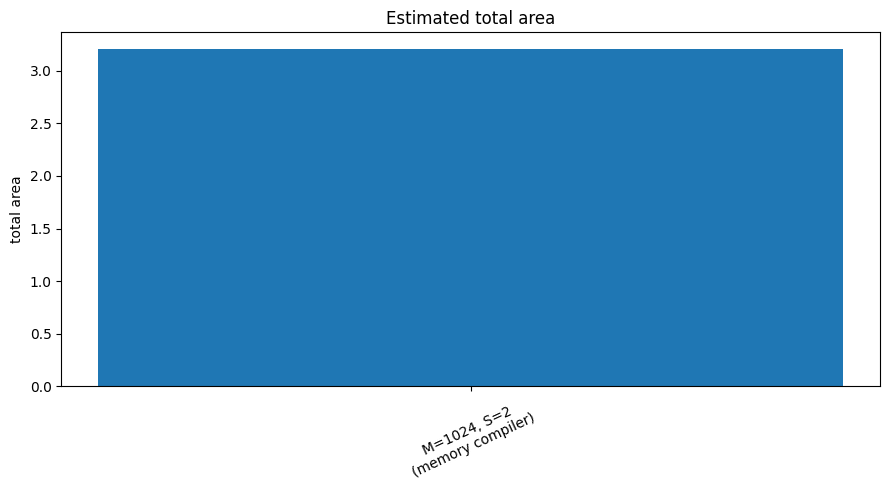

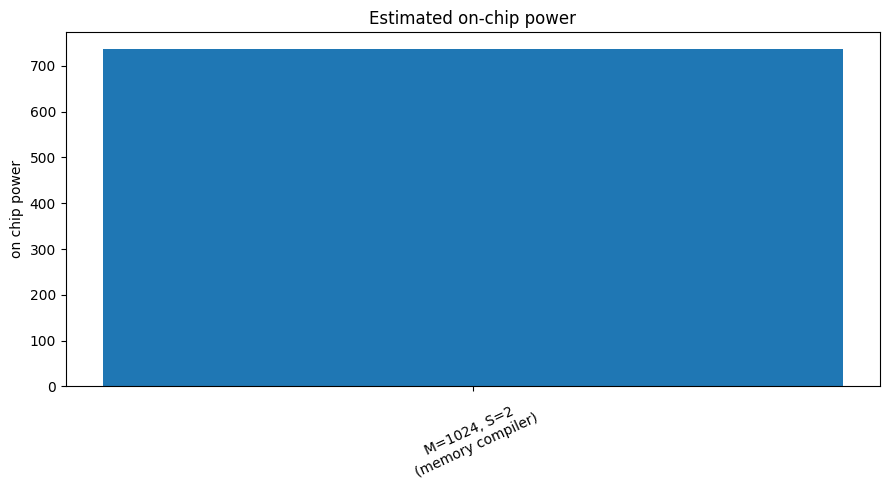

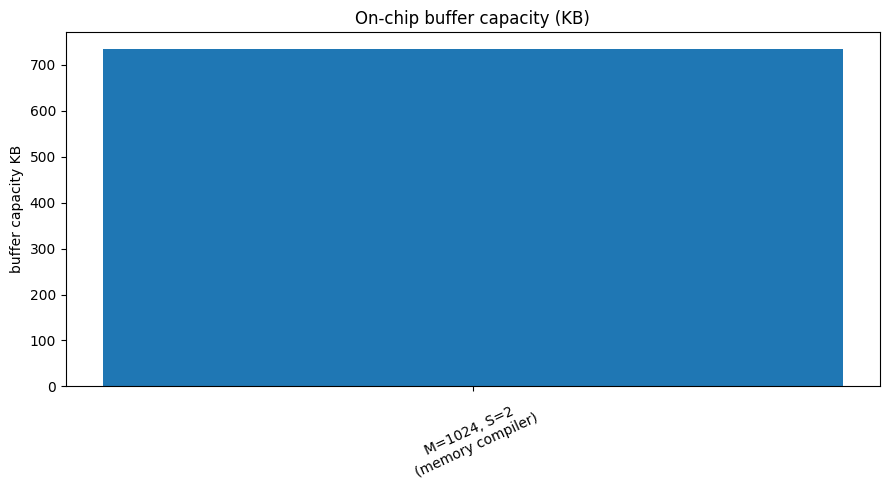

Plots saved under: /kaggle/working/focus_reproduction


In [12]:
valid=sweep[sweep.status=='OK'].copy()
if valid.empty:
    print('No successful sweep rows to graph.')
else:
    valid['configuration']=valid.apply(lambda r: f"M={int(r.m_tile_size)}, S={int(r.scatter_vectors)}\n({r.buffer_method})",axis=1)
    for metric,title,filename in [
        ('total_area','Estimated total area','focus_area_sweep.png'),
        ('on_chip_power','Estimated on-chip power','focus_power_sweep.png'),
        ('buffer_capacity_KB','On-chip buffer capacity (KB)','focus_buffer_sweep.png')]:
        plot_df=valid.dropna(subset=[metric])
        if plot_df.empty: continue
        fig,ax=plt.subplots(figsize=(max(9,len(plot_df)*1.7),5))
        ax.bar(plot_df.configuration,plot_df[metric])
        ax.set_title(title)
        ax.set_ylabel(metric.replace('_',' '))
        ax.tick_params(axis='x',rotation=25)
        fig.tight_layout()
        fig.savefig(OUT/filename,dpi=180,bbox_inches='tight')
        plt.show()
    print('Plots saved under:',OUT)

## 8 — Compare the original four architectures

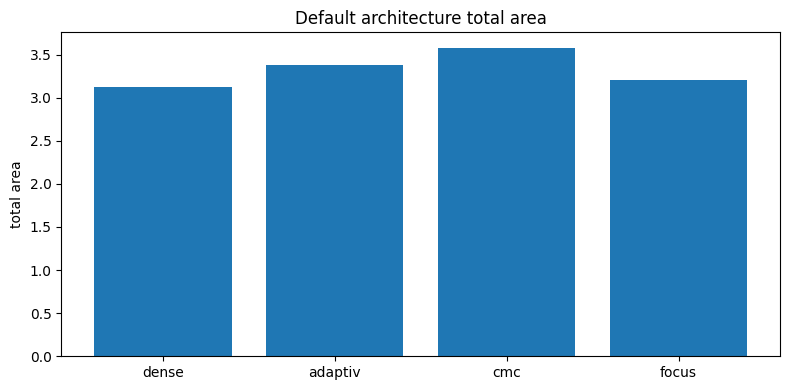

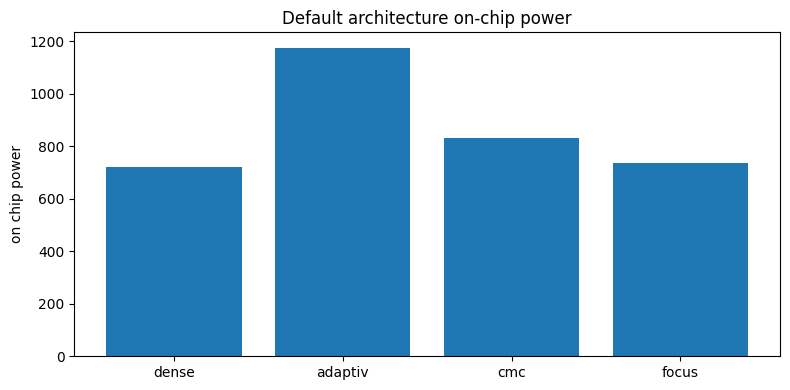

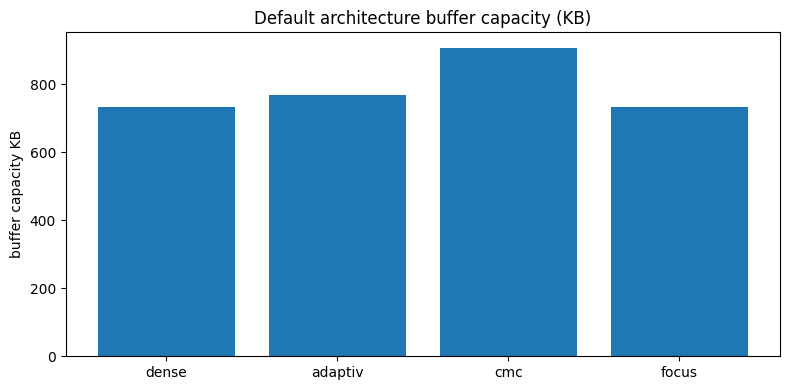

Focus area overhead vs dense: 2.77%
Focus on-chip power difference vs dense: 2.21%


In [13]:
for metric,title,filename in [
    ('total_area','Default architecture total area','default_area.png'),
    ('on_chip_power','Default architecture on-chip power','default_power.png'),
    ('buffer_capacity_KB','Default architecture buffer capacity (KB)','default_buffer.png')]:
    fig,ax=plt.subplots(figsize=(8,4))
    ax.bar(baseline.architecture,baseline[metric])
    ax.set_title(title);ax.set_ylabel(metric.replace('_',' '))
    fig.tight_layout();fig.savefig(OUT/filename,dpi=180)
    plt.show()

if {'dense','focus'}.issubset(set(baseline.architecture)):
    dense=baseline.set_index('architecture').loc['dense']
    focus=baseline.set_index('architecture').loc['focus']
    print('Focus area overhead vs dense: {:.2f}%'.format(100*(focus.total_area/dense.total_area-1)))
    print('Focus on-chip power difference vs dense: {:.2f}%'.format(100*(focus.on_chip_power/dense.on_chip_power-1)))

## 9 — Results and interpretation

Outputs in `/kaggle/working/focus_reproduction/` include the original estimator log, default architecture CSV, sweep CSV, per-configuration logs and PNG figures.

**What the experiments establish:** estimated hardware area, on-chip power, and buffer capacity under the authors’ component/memory models.

**What they do not establish:** new synthesis results, actual chip power measurements, inference speedup, or per-inference energy. For the latter, Focus requires workload-dependent sparsity traces or equivalent data.

**Comparison caution:** default configuration uses memory-compiler estimates; modified configurations use CACTI, so comparisons mix two memory characterization sources. To isolate parameter effects, run all compared configurations through CACTI (including the default using `force_cacti=True`) after CACTI works and confirm the relevant output units and assumptions.

In [20]:
from IPython.display import FileLink, display
from pathlib import Path

zip_path = Path("/kaggle/working/focus_reproduction.zip")

assert zip_path.exists(), "ZIP file not found!"

print(f"File size: {zip_path.stat().st_size / 1024:.1f} KB")

display(FileLink(
    "focus_reproduction.zip",
    url_prefix="/files/"
))

File size: 189.3 KB


/kaggle/working/focus_reproduction.zip